<a href="https://colab.research.google.com/github/mdet0001-ai/MMA3001.Project/blob/main/MMA3001_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
# ============================================================
# MMA3001 PROJECT - ENVIRONMENTAL DATA SETUP
# ============================================================
#
# This cell:
#   1. Downloads / updates the GitHub repository
#   2. Finds the environmental sensor ZIP file
#   3. Extracts the CSV into temporary Colab storage
#   4. Creates ENV_CSV, which will be used for all analysis
#
# ============================================================

# ============================================================
# CELL 1 - SETUP
# ============================================================

# ------------------------------------------------------------
# 1. Import required libraries
# ------------------------------------------------------------

from pathlib import Path
import subprocess
import zipfile
import pandas as pd


# ------------------------------------------------------------
# 2. Define repository information
# ------------------------------------------------------------

GITHUB_REPO = "https://github.com/mdet0001-ai/MMA3001.Project.git"

# Local copy of the GitHub repository in Colab
REPO = Path("/content/MMA3001_repo")

# Temporary folder where the large CSV will be extracted
# This is deliberately OUTSIDE the GitHub repository.
DATA_FOLDER = Path("/content/MMA3001_environmental_data")


# ------------------------------------------------------------
# 3. Download or update the GitHub repository
# ------------------------------------------------------------

if not REPO.exists():

    print("Cloning GitHub repository...")

    subprocess.run(
        [
            "git",
            "clone",
            GITHUB_REPO,
            str(REPO)
        ],
        check=True
    )

else:

    print("Repository already exists. Updating from GitHub...")

    subprocess.run(
        [
            "git",
            "pull",
            "origin",
            "main"
        ],
        cwd=REPO,
        check=True
    )


print("Repository ready.")


# ------------------------------------------------------------
# 4. Find the environmental sensor ZIP file
# ------------------------------------------------------------

zip_matches = list(
    REPO.rglob("5EnvSensor_MayToDec2024_180kRows.zip")
)

if len(zip_matches) == 0:
    raise FileNotFoundError(
        "Could not find 5EnvSensor_MayToDec2024_180kRows.zip "
        "inside the GitHub repository."
    )

ENV_ZIP = zip_matches[0]

print("\nEnvironmental dataset found:")
print(ENV_ZIP)


# ------------------------------------------------------------
# 5. Create temporary extraction folder
# ------------------------------------------------------------

DATA_FOLDER.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 6. Extract the environmental dataset
# ------------------------------------------------------------

print("\nExtracting environmental dataset...")

with zipfile.ZipFile(ENV_ZIP, "r") as zip_ref:

    zip_ref.extractall(DATA_FOLDER)


print("Extraction complete.")


# ------------------------------------------------------------
# 7. Find the extracted CSV
# ------------------------------------------------------------

csv_matches = list(
    DATA_FOLDER.rglob("5EnvSensor_MayToDec2024_180kRows.csv")
)

if len(csv_matches) == 0:
    raise FileNotFoundError(
        "ZIP was extracted, but the environmental CSV "
        "could not be found."
    )

ENV_CSV = csv_matches[0]


print("\nEnvironmental CSV ready:")
print(ENV_CSV)


# ------------------------------------------------------------
# 8. Check that pandas can read the dataset
# ------------------------------------------------------------

df_test = pd.read_csv(
    ENV_CSV,
    nrows=5
)

print("\nFirst 5 rows:")
display(df_test)

print("\nColumns:")
print(df_test.columns.tolist())

Repository already exists. Updating from GitHub...
Repository ready.

Environmental dataset found:
/content/MMA3001_repo/data/raw/5EnvSensor_MayToDec2024_180kRows.zip

Extracting environmental dataset...
Extraction complete.

Environmental CSV ready:
/content/MMA3001_environmental_data/5EnvSensor_MayToDec2024_180kRows.csv

First 5 rows:


,id,sensorid,devicetype,jsondata,status,processing_errors,createdate,processdate
0,2,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 03:11:58.210358+11,2024-02-29 03:11:58.210358+11
1,4,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 17:09:08.833822+11,2024-02-29 17:09:08.833822+11
2,5,6012002000326,env,"[{""values"": [{""time"": 1702270857, ""value"": 4.1...",Processed,NaN,2024-02-29 17:09:12.444245+11,2024-02-29 17:09:12.444245+11
3,16,6012002000777,env,"[{""values"": [{""time"": 1683326565, ""value"": 4.1...",Processed,NaN,2024-02-29 17:10:24.443407+11,2024-02-29 17:10:24.443407+11
4,24,6012002000869,env,"[{""values"": [{""time"": 1709186696, ""value"": 4.1...",Processed,NaN,2024-02-29 17:11:11.348578+11,2024-02-29 17:11:11.348578+11



Columns:
['id', 'sensorid', 'devicetype', 'jsondata', 'status', 'processing_errors', 'createdate', 'processdate']


Downloading project repo from GitHub, locate env sensor data

In [6]:
# ============================================================
# CELL 2 - PARSE ENVIRONMENTAL SENSOR DATA
# ============================================================

import json
import pandas as pd


# ------------------------------------------------------------
# 1. Load raw environmental dataset
# ------------------------------------------------------------

raw_env = pd.read_csv(ENV_CSV)

print("Raw CSV rows:", len(raw_env))


# ------------------------------------------------------------
# 2. Convert JSON sensor data into normal columns
# ------------------------------------------------------------

variable_map = {
    "Battery": "Battery",
    "Carbon dioxide": "CO2",
    "Humidity": "Humidity",
    "Formaldehyde": "Formaldehyde",
    "Pressure": "Pressure",
    "Temperature": "Temperature",
    "Light Volatile Organic Compounds": "VOC",
    "Particulate matter 1": "PM1",
    "Particulate matter 2.5": "PM2_5",
    "Particulate matter 4": "PM4",
    "Particulate matter 10": "PM10"
}

records = []

for _, row in raw_env.iterrows():
    try:
        sensor_json = json.loads(row["jsondata"])

        record = {
            "SensorID": row["sensorid"]
        }

        measurement_time = None

        for measurement in sensor_json:

            variable_info = measurement.get("variable", {})
            variable_name = variable_info.get("name")

            if variable_name in variable_map:

                values = measurement.get("values", [])

                if len(values) > 0:

                    record[
                        variable_map[variable_name]
                    ] = values[0].get("value")

                    # Use embedded measurement time
                    if measurement_time is None:
                        measurement_time = values[0].get("time")

        record["UnixTime"] = measurement_time

        records.append(record)

    except (json.JSONDecodeError, TypeError, KeyError):
        continue


# ------------------------------------------------------------
# 3. Create parsed DataFrame
# ------------------------------------------------------------

env_all = pd.DataFrame(records)

print("Parsed rows:", len(env_all))


# ------------------------------------------------------------
# 4. Convert Unix timestamp to Melbourne time
# ------------------------------------------------------------

env_all["Time"] = pd.to_datetime(
    env_all["UnixTime"],
    unit="s",
    utc=True
).dt.tz_convert("Australia/Melbourne")

env_all = env_all.drop(
    columns=["UnixTime"]
)


# ------------------------------------------------------------
# 5. Remove duplicate physical measurements
# ------------------------------------------------------------

env_data = (
    env_all
    .drop_duplicates(
        subset=["SensorID", "Time"]
    )
    .sort_values(
        ["SensorID", "Time"]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

print(
    "Unique sensor measurements:",
    len(env_data)
)

display(
    env_data.head()
)

print(
    "\nColumns:", env_data.columns.tolist()
)

Raw CSV rows: 179447
Parsed rows: 179447
Unique sensor measurements: 42843


,SensorID,Battery,CO2,Humidity,Formaldehyde,Pressure,Temperature,VOC,PM1,PM4,PM2_5,PM10,Time
0,6012002000227,4.1875,666,69,4.0,1011,24.0,15.0,3.0,3.0,3.0,3.0,2023-12-11 16:07:53+11:00
1,6012002000241,4.1875,603,66,6.0,1011,23.8,14.0,8.0,9.0,9.0,9.0,2023-12-11 16:52:45+11:00
2,6012002000241,4.1875,447,45,NaN,1023,15.5,NaN,2.0,2.0,2.0,2.0,2025-05-19 23:08:04+10:00
3,6012002000326,4.1875,525,68,5.0,1012,23.8,7.0,6.0,6.0,6.0,6.0,2023-12-11 16:00:57+11:00
4,6012002000326,4.1875,410,60,NaN,1005,19.0,0.0,0.0,0.0,0.0,0.0,2025-09-07 20:09:30+10:00



Columns: ['SensorID', 'Battery', 'CO2', 'Humidity', 'Formaldehyde', 'Pressure', 'Temperature', 'VOC', 'PM1', 'PM4', 'PM2_5', 'PM10', 'Time']


Pulling all the useful data points. data/time is set to melbrourne time and duplicate sensor data and outputs are removed, reducing 179447 raw data points to 42843 useful data points.

In [7]:
# ============================================================
# CELL 3 - INSPECT CLEANED ENVIRONMENTAL DATA
# ============================================================


# ------------------------------------------------------------
# 1. Basic dataset information
# ------------------------------------------------------------

print("Total unique measurements:", len(env_data))
print("Number of sensors:", env_data["SensorID"].nunique())

print("\nDate range:")
print("Start:", env_data["Time"].min())
print("End:  ", env_data["Time"].max())


# ------------------------------------------------------------
# 2. Number of missing values in each variable
# ------------------------------------------------------------

print("\nMissing values:")
print(
    env_data.isna().sum()
)


# ------------------------------------------------------------
# 3. Percentage of missing values
# ------------------------------------------------------------

print("\nMissing values (%):")

missing_percent = (
    env_data.isna().mean() * 100
).round(2)

print(missing_percent)


# ------------------------------------------------------------
# 4. Basic statistics for the environmental measurements
# ------------------------------------------------------------

variables = [
    "CO2",
    "Temperature",
    "Humidity",
    "Pressure",
    "VOC",
    "PM2_5"
]

display(
    env_data[variables].describe()
)


# ------------------------------------------------------------
# 5. Measurements available for each sensor
# ------------------------------------------------------------

sensor_counts = (
    env_data["SensorID"]
    .value_counts()
)

print("\nMeasurements per sensor:")

display(
    sensor_counts
    .rename("Number of Measurements")
    .to_frame()
)



Total unique measurements: 42843
Number of sensors: 5

Date range:
Start: 2023-05-06 08:42:45+10:00
End:   2026-04-22 23:12:41+10:00

Missing values:
SensorID            0
Battery             0
CO2                 0
Humidity            0
Formaldehyde    29039
Pressure            0
Temperature         0
VOC                 1
PM1              1693
PM4              1693
PM2_5            1693
PM10             1693
Time                0
dtype: int64

Missing values (%):
SensorID         0.00
Battery          0.00
CO2              0.00
Humidity         0.00
Formaldehyde    67.78
Pressure         0.00
Temperature      0.00
VOC              0.00
PM1              3.95
PM4              3.95
PM2_5            3.95
PM10             3.95
Time             0.00
dtype: float64


,CO2,Temperature,Humidity,Pressure,VOC,PM2_5
count,42843.000000,42843.000000,42843.000000,42843.000000,42842.000000,41150.000000
mean,451.695750,21.553906,50.958663,1011.745209,12.408338,1.620875
std,34.378194,3.459916,10.148825,7.301158,130.468851,5.031844
min,400.000000,11.800000,17.000000,988.000000,0.000000,0.000000
25%,431.000000,19.000000,44.000000,1007.000000,0.000000,0.000000
50%,443.000000,22.000000,50.000000,1011.000000,0.000000,0.000000
75%,461.000000,23.500000,58.000000,1017.000000,0.000000,2.000000
max,1387.000000,37.500000,84.000000,1028.000000,8051.000000,105.000000



Measurements per sensor:


,Number of Measurements
SensorID,
6012002000326,29039
6012002000869,13800
6012002000241,2
6012002000227,1
6012002000777,1


Identifying different sensor IDs and determining which input sensor data could be used by % missing data

In [8]:
# ============================================================
# CELL 4 - SELECT THE USEFUL SENSOR DATA
# ============================================================


# ------------------------------------------------------------
# 1. Keep only sensors with enough measurements
# ------------------------------------------------------------

useful_sensors = [
    6012002000326,
    6012002000869
]

analysis_data = env_data[
    env_data["SensorID"].isin(useful_sensors)
].copy()


# ------------------------------------------------------------
# 2. Drop Formaldehyde
#
# Around 68% of Formaldehyde measurements are missing,
# so it will not be used in this project.
# ------------------------------------------------------------

analysis_data = analysis_data.drop(
    columns=["Formaldehyde"]
)


# ------------------------------------------------------------
# 3. Display amount of usable data
# ------------------------------------------------------------

print("Measurements retained:", len(analysis_data))

print("\nMeasurements per sensor:")
print(
    analysis_data["SensorID"]
    .value_counts()
)


# ------------------------------------------------------------
# 4. Check date range for each sensor
# ------------------------------------------------------------

sensor_dates = (
    analysis_data
    .groupby("SensorID")["Time"]
    .agg(["min", "max", "count"])
)

sensor_dates.columns = [
    "First Measurement",
    "Last Measurement",
    "Number of Measurements"
]

display(sensor_dates)

Measurements retained: 42839

Measurements per sensor:
SensorID
6012002000326    29039
6012002000869    13800
Name: count, dtype: int64


,First Measurement,Last Measurement,Number of Measurements
SensorID,,,
6012002000326,2023-12-11 16:00:57+11:00,2026-04-22 23:12:41+10:00,29039
6012002000869,2024-02-29 17:04:56+11:00,2024-06-14 03:45:44+10:00,13800


The two sensors shosen are the only ones containing a reasonable number of data points available for use

In [9]:
# ============================================================
# CELL 5 - CHECK MONTHLY DATA COVERAGE
# ============================================================


# ------------------------------------------------------------
# 1. Create a year-month column
# ------------------------------------------------------------

analysis_data["Month"] = (
    analysis_data["Time"]
    .dt.tz_localize(None)
    .dt.to_period("M")
)


# ------------------------------------------------------------
# 2. Count measurements per month for each sensor
# ------------------------------------------------------------

monthly_counts = (
    analysis_data
    .groupby(["SensorID", "Month"])
    .size()
    .reset_index(name="Measurements")
)


# ------------------------------------------------------------
# 3. Display monthly data coverage
# ------------------------------------------------------------

display(monthly_counts)

,SensorID,Month,Measurements
0,6012002000326,2023-12,1
1,6012002000326,2025-09,2576
2,6012002000326,2025-10,4154
3,6012002000326,2025-11,3722
4,6012002000326,2025-12,4193
5,6012002000326,2026-01,4067
6,6012002000326,2026-02,3155
7,6012002000326,2026-03,4195
8,6012002000326,2026-04,2976
9,6012002000869,2024-02,31


Coallating data based on sensor and month to determine relationships

In [10]:
# ============================================================
# CELL 6 - CREATE MAIN SENSOR DATASET
# ============================================================

# Sensor chosen for the main investigation
MAIN_SENSOR = 6012002000869


# ------------------------------------------------------------
# 1. Select the main sensor
# ------------------------------------------------------------

main_data = analysis_data[
    analysis_data["SensorID"] == MAIN_SENSOR
].copy()


# ------------------------------------------------------------
# 2. Sort measurements chronologically
# ------------------------------------------------------------

main_data = main_data.sort_values(
    "Time"
).reset_index(drop=True)


# ------------------------------------------------------------
# 3. Remove rows with missing values in variables
#    that will be used for modelling
# ------------------------------------------------------------

model_variables = [
    "CO2",
    "Temperature",
    "Humidity",
    "Pressure",
    "VOC",
    "PM2_5"
]

main_data = main_data.dropna(
    subset=model_variables
).reset_index(drop=True)


# ------------------------------------------------------------
# 4. Display final dataset information
# ------------------------------------------------------------

print("Sensor:", MAIN_SENSOR)
print("Number of usable measurements:", len(main_data))

print("\nDate range:")
print("Start:", main_data["Time"].min())
print("End:  ", main_data["Time"].max())

print("\nVariables:")
print(model_variables)

display(
    main_data[
        ["Time"] + model_variables
    ].head(10)
)

Sensor: 6012002000869
Number of usable measurements: 13800

Date range:
Start: 2024-02-29 17:04:56+11:00
End:   2024-06-14 03:45:44+10:00

Variables:
['CO2', 'Temperature', 'Humidity', 'Pressure', 'VOC', 'PM2_5']


,Time,CO2,Temperature,Humidity,Pressure,VOC,PM2_5
0,2024-02-29 17:04:56+11:00,465,24.3,56,1010,0.0,2.0
1,2024-02-29 17:14:57+11:00,445,24.0,56,1010,0.0,4.0
2,2024-02-29 17:34:57+11:00,471,23.8,56,1010,0.0,2.0
3,2024-02-29 17:44:57+11:00,457,23.8,56,1010,0.0,2.0
4,2024-02-29 17:54:57+11:00,455,23.8,57,1010,0.0,2.0
5,2024-02-29 18:14:57+11:00,456,23.5,58,1010,0.0,4.0
6,2024-02-29 18:24:57+11:00,456,23.3,58,1010,0.0,1.0
7,2024-02-29 18:34:57+11:00,473,23.3,59,1010,0.0,1.0
8,2024-02-29 18:54:57+11:00,501,23.3,59,1010,0.0,2.0
9,2024-02-29 19:04:57+11:00,513,23.0,59,1010,0.0,1.0


Sensor 6012002000869 is chosen and divided into different output data sets

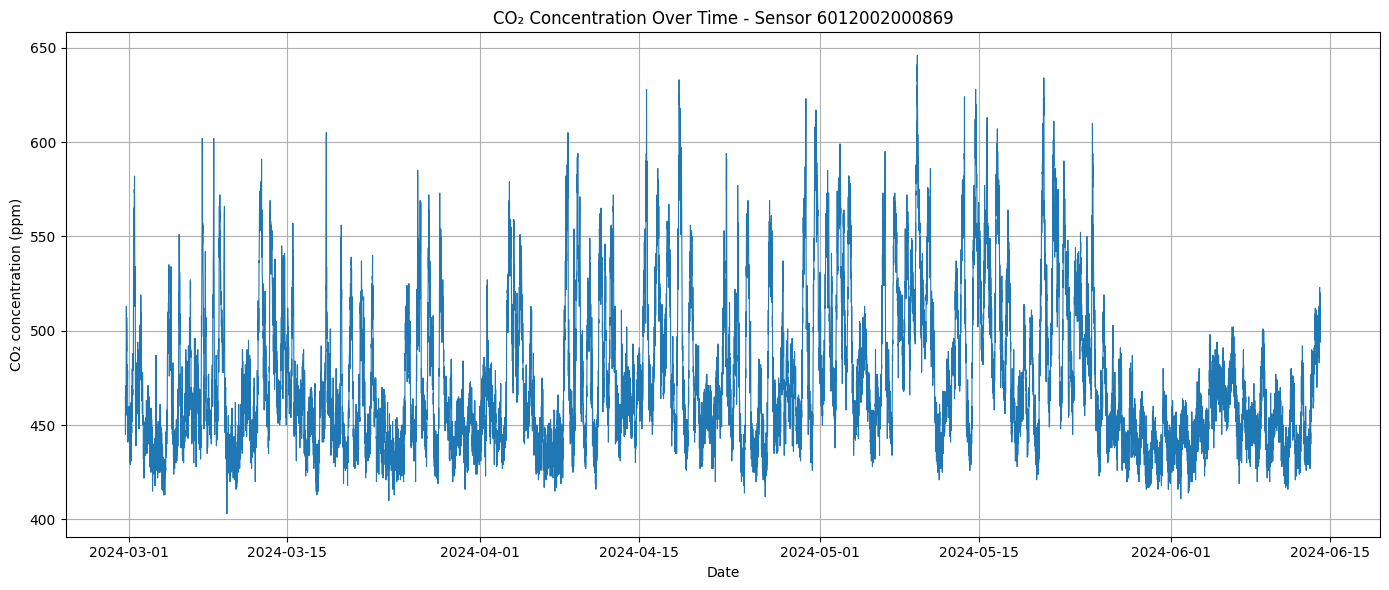

In [11]:
# ============================================================
# CELL 7 - CO2 CONCENTRATION OVER TIME
# ============================================================

import matplotlib.pyplot as plt


plt.figure(figsize=(14, 6))

plt.plot(
    main_data["Time"],
    main_data["CO2"],
    linewidth=0.8
)

plt.xlabel("Date")
plt.ylabel("CO₂ concentration (ppm)")

plt.title(
    f"CO₂ Concentration Over Time - Sensor {MAIN_SENSOR}"
)

plt.grid(True)
plt.tight_layout()

plt.show()

Using the chosen sensor, measure CO2 concentration over time

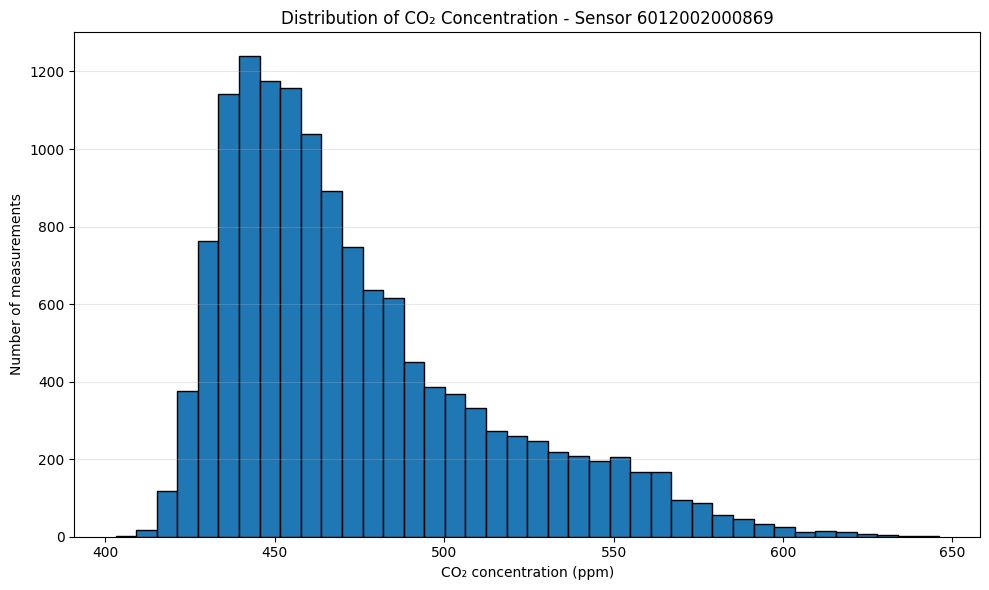

In [12]:
# ============================================================
# CELL 8 - CO2 DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 6))

plt.hist(
    main_data["CO2"],
    bins=40,
    edgecolor="black"
)

plt.xlabel("CO₂ concentration (ppm)")
plt.ylabel("Number of measurements")

plt.title(
    f"Distribution of CO₂ Concentration - Sensor {MAIN_SENSOR}"
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

Using the chosen sensor, a histogram showing the distribution of different concentrations

In [13]:
# ============================================================
# CELL 9 - CORRELATION WITH CO2
# ============================================================

# Variables we want to compare with CO2
variables = [
    "CO2",
    "Temperature",
    "Humidity",
    "Pressure",
    "VOC",
    "PM2_5"
]


# ------------------------------------------------------------
# Calculate correlation matrix
# ------------------------------------------------------------

correlation_matrix = (
    main_data[variables]
    .corr()
)


# ------------------------------------------------------------
# Show correlation of each variable with CO2
# ------------------------------------------------------------

co2_correlations = (
    correlation_matrix["CO2"]
    .sort_values(ascending=False)
)

print("Correlation with CO2:")
display(co2_correlations.to_frame("Correlation"))

Correlation with CO2:


,Correlation
CO2,1.000000
Pressure,0.304985
Temperature,0.170572
VOC,0.042331
Humidity,0.010713
PM2_5,-0.078499


Using the chosen sensor, the correlation with CO2 from chosen measurement data is determine, with a 1:1 correltation with CO2 standing as a controlled variable

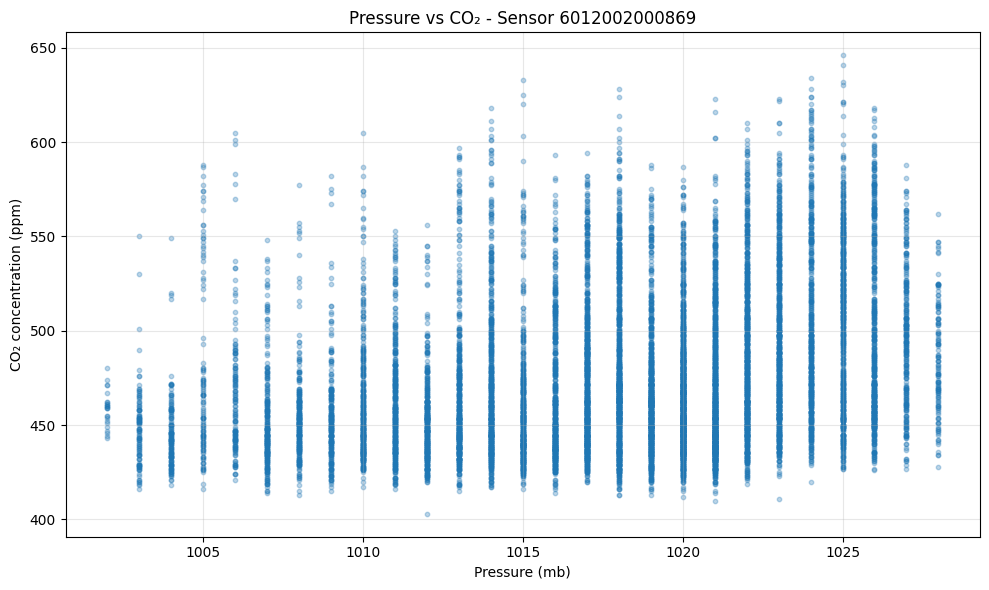

In [14]:
# ============================================================
# CELL 10 - PRESSURE VS CO2
# ============================================================

plt.figure(figsize=(10, 6))

plt.scatter(
    main_data["Pressure"],
    main_data["CO2"],
    alpha=0.3,
    s=10
)

plt.xlabel("Pressure (mb)")
plt.ylabel("CO₂ concentration (ppm)")

plt.title(
    f"Pressure vs CO₂ - Sensor {MAIN_SENSOR}"
)

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

Using the chosen sensor, measure CO2 concentration over varying pressures

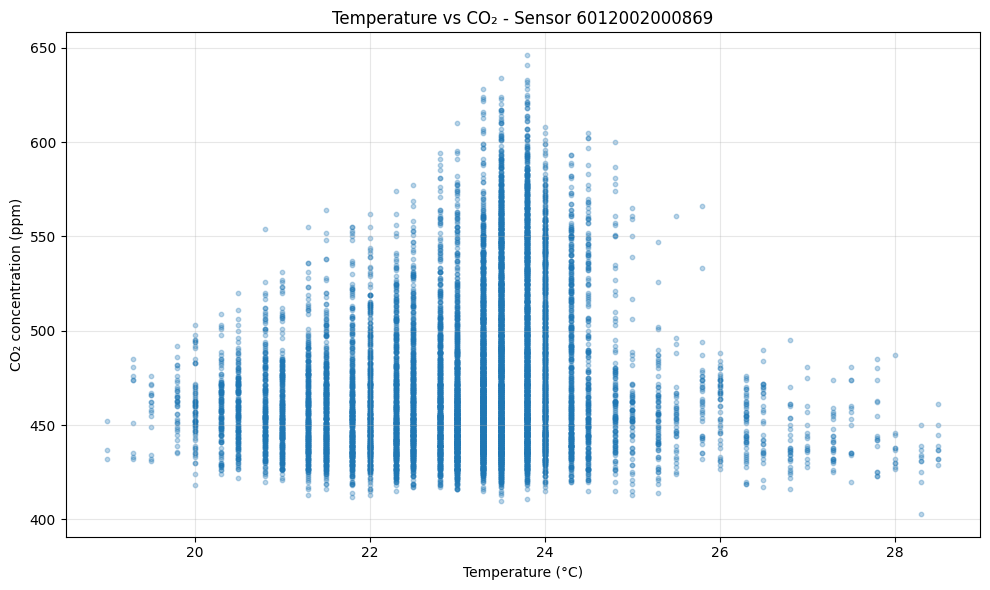

In [15]:
# ============================================================
# CELL 11 - TEMPERATURE VS CO2
# ============================================================

plt.figure(figsize=(10, 6))

plt.scatter(
    main_data["Temperature"],
    main_data["CO2"],
    alpha=0.3,
    s=10
)

plt.xlabel("Temperature (°C)")
plt.ylabel("CO₂ concentration (ppm)")

plt.title(
    f"Temperature vs CO₂ - Sensor {MAIN_SENSOR}"
)

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

Using the chosen sensor,measure CO2 concentration over different ambient room temperatures

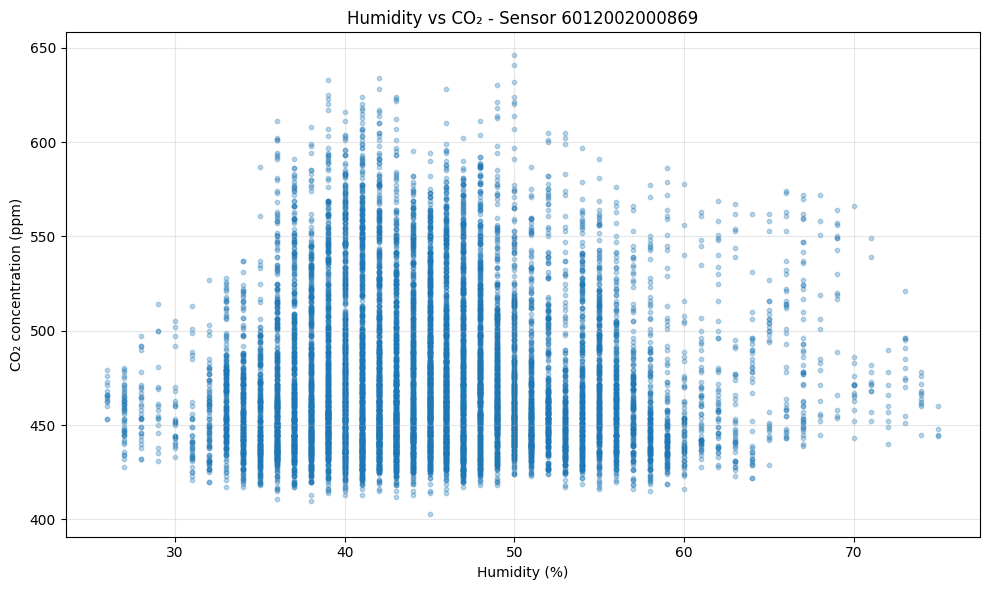

In [16]:
# ============================================================
# CELL 12 - HUMIDITY VS CO2
# ============================================================

plt.figure(figsize=(10, 6))

plt.scatter(
    main_data["Humidity"],
    main_data["CO2"],
    alpha=0.3,
    s=10
)

plt.xlabel("Humidity (%)")
plt.ylabel("CO₂ concentration (ppm)")

plt.title(
    f"Humidity vs CO₂ - Sensor {MAIN_SENSOR}"
)

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

Using the chosen sensor, measure CO2 concentration againsts different room humidities. No real correlation is visible agreeing with a correlation coefficient of 0.011.

In [17]:
# ============================================================
# CELL 13 - INSPECT VOC DATA
# ============================================================

print("VOC statistics:\n")

print(
    main_data["VOC"]
    .describe()
)

print("\nVOC percentiles:")

print(
    main_data["VOC"].quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99, 1.00]
    )
)

VOC statistics:

count    13800.000000
mean        10.458841
std         35.391380
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max        729.000000
Name: VOC, dtype: float64

VOC percentiles:
0.50      0.0
0.75      1.0
0.90     27.0
0.95     60.0
0.99    177.0
1.00    729.0
Name: VOC, dtype: float64


Using the chosen sensor, Inspecting the VOC data as the majority appeared to be skewed, zeros or below 1.

In [18]:
# ============================================================
# CELL 14 - CREATE TRAINING AND TESTING DATA
# ============================================================


# ------------------------------------------------------------
# 1. Define model inputs and output
# ------------------------------------------------------------

features = [
    "Temperature",
    "Humidity",
    "Pressure",
    "VOC",
    "PM2_5"
]

target = "CO2"


# ------------------------------------------------------------
# 2. Find the 80% split point
# ------------------------------------------------------------

split_index = int(len(main_data) * 0.80)


# ------------------------------------------------------------
# 3. Split chronologically
# ------------------------------------------------------------

train_data = main_data.iloc[:split_index].copy()
test_data = main_data.iloc[split_index:].copy()


# ------------------------------------------------------------
# 4. Create X (inputs) and y (CO2 output)
# ------------------------------------------------------------

X_train = train_data[features]
y_train = train_data[target]

X_test = test_data[features]
y_test = test_data[target]


# ------------------------------------------------------------
# 5. Check the split
# ------------------------------------------------------------

print("Total measurements:", len(main_data))

print("\nTraining measurements:", len(X_train))
print("Testing measurements:", len(X_test))

print("\nTraining period:")
print(train_data["Time"].min(), "to", train_data["Time"].max())

print("\nTesting period:")
print(test_data["Time"].min(), "to", test_data["Time"].max())

print("\nFeatures used:")
print(features)

# for myself on what this means - training data = first 80% and testing data = last 20%

Total measurements: 13800

Training measurements: 11040
Testing measurements: 2760

Training period:
2024-02-29 17:04:56+11:00 to 2024-05-24 16:05:37+10:00

Testing period:
2024-05-24 16:15:37+10:00 to 2024-06-14 03:45:44+10:00

Features used:
['Temperature', 'Humidity', 'Pressure', 'VOC', 'PM2_5']


For myself on what this means - training data = first 80% and testing data = last 20%
Additionally - test set is lat may to mid june meaning seasonal impacts are not accounted for

In [19]:
# ============================================================
# CELL 15 - TRAIN LINEAR REGRESSION MODEL
# ============================================================

from sklearn.linear_model import LinearRegression


# ------------------------------------------------------------
# 1. Create the Linear Regression model
# ------------------------------------------------------------

linear_model = LinearRegression()


# ------------------------------------------------------------
# 2. Train the model using the training data
# ------------------------------------------------------------

linear_model.fit(
    X_train,
    y_train
)


# ------------------------------------------------------------
# 3. Make CO2 predictions using the test data
# ------------------------------------------------------------

y_pred_linear = linear_model.predict(
    X_test
)


# ------------------------------------------------------------
# 4. Display model coefficients
# ------------------------------------------------------------

print("Linear Regression coefficients:\n")

for feature, coefficient in zip(
    features,
    linear_model.coef_
):

    print(
        f"{feature}: {coefficient:.4f}"
    )


print(
    "\nIntercept:",
    round(linear_model.intercept_, 4)
)


# ------------------------------------------------------------
# 5. Show first few predictions
# ------------------------------------------------------------

prediction_check = test_data[
    ["Time", "CO2"]
].copy()

prediction_check["Predicted_CO2"] = y_pred_linear

display(
    prediction_check.head(10)
)

Linear Regression coefficients:

Temperature: 7.9983
Humidity: 0.5575
Pressure: 2.6097
VOC: 0.2677
PM2_5: -0.4061

Intercept: -2388.6774


,Time,CO2,Predicted_CO2
11040,2024-05-24 16:15:37+10:00,491,489.584115
11041,2024-05-24 16:25:37+10:00,501,492.193770
11042,2024-05-24 16:35:37+10:00,486,490.200378
11043,2024-05-24 16:45:37+10:00,489,490.200378
11044,2024-05-24 16:55:37+10:00,503,489.388169
11045,2024-05-24 17:05:37+10:00,476,492.193770
11046,2024-05-24 17:15:37+10:00,477,489.990219
11047,2024-05-24 17:25:36+10:00,478,489.584115
11048,2024-05-24 17:35:36+10:00,484,489.584115
11049,2024-05-24 17:45:36+10:00,505,489.584115


Linear regression model for CO2 output based on all inputs. Coefficents where calulated through the squared difference between measured and predicted CO2 for all individual input variables.

In [20]:
# ============================================================
# CELL 16 - EVALUATE LINEAR REGRESSION
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np


# ------------------------------------------------------------
# 1. Calculate evaluation metrics
# ------------------------------------------------------------

mae_linear = mean_absolute_error(
    y_test,
    y_pred_linear
)

rmse_linear = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_linear
    )
)

r2_linear = r2_score(
    y_test,
    y_pred_linear
)


# ------------------------------------------------------------
# 2. Display results
# ------------------------------------------------------------

print("LINEAR REGRESSION PERFORMANCE")
print("-----------------------------")

print(
    f"MAE:  {mae_linear:.2f} ppm"
)

print(
    f"RMSE: {rmse_linear:.2f} ppm"
)

print(
    f"R²:   {r2_linear:.3f}"
)

LINEAR REGRESSION PERFORMANCE
-----------------------------
MAE:  27.02 ppm
RMSE: 33.61 ppm
R²:   -1.314


Evaluating thee linear regression model: The negative R^2 value suggests the model performs worse than the simple baseline that predicts the average CO2 concentration. Thus suggesting, and agreeing with the correlation coefficents, that the environmental variables struggle to adequetly represent their relationship to CO2 concentration with a linear model.

In [21]:
# ============================================================
# CELL 17 - TRAIN DECISION TREE REGRESSION MODEL
# ============================================================

from sklearn.tree import DecisionTreeRegressor


# ------------------------------------------------------------
# 1. Create the Decision Tree model
# ------------------------------------------------------------

decision_tree = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)


# ------------------------------------------------------------
# 2. Train the model
# ------------------------------------------------------------

decision_tree.fit(
    X_train,
    y_train
)


# ------------------------------------------------------------
# 3. Predict CO2 for the unseen test data
# ------------------------------------------------------------

y_pred_tree = decision_tree.predict(
    X_test
)


# ------------------------------------------------------------
# 4. Show first few predictions
# ------------------------------------------------------------

tree_prediction_check = test_data[
    ["Time", "CO2"]
].copy()

tree_prediction_check["Predicted_CO2"] = y_pred_tree


display(
    tree_prediction_check.head(10)
)

,Time,CO2,Predicted_CO2
11040,2024-05-24 16:15:37+10:00,491,489.385382
11041,2024-05-24 16:25:37+10:00,501,489.385382
11042,2024-05-24 16:35:37+10:00,486,489.385382
11043,2024-05-24 16:45:37+10:00,489,489.385382
11044,2024-05-24 16:55:37+10:00,503,489.385382
11045,2024-05-24 17:05:37+10:00,476,489.385382
11046,2024-05-24 17:15:37+10:00,477,489.385382
11047,2024-05-24 17:25:36+10:00,478,489.385382
11048,2024-05-24 17:35:36+10:00,484,489.385382
11049,2024-05-24 17:45:36+10:00,505,489.385382


In [22]:
# ============================================================
# CELL 18 - EVALUATE DECISION TREE REGRESSION
# ============================================================


# ------------------------------------------------------------
# 1. Calculate evaluation metrics
# ------------------------------------------------------------

mae_tree = mean_absolute_error(
    y_test,
    y_pred_tree
)

rmse_tree = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_tree
    )
)

r2_tree = r2_score(
    y_test,
    y_pred_tree
)


# ------------------------------------------------------------
# 2. Display results
# ------------------------------------------------------------

print("DECISION TREE REGRESSION PERFORMANCE")
print("------------------------------------")

print(
    f"MAE:  {mae_tree:.2f} ppm"
)

print(
    f"RMSE: {rmse_tree:.2f} ppm"
)

print(
    f"R²:   {r2_tree:.3f}"
)

DECISION TREE REGRESSION PERFORMANCE
------------------------------------
MAE:  35.39 ppm
RMSE: 45.04 ppm
R²:   -3.157


The Decision Tree Regression model performed worse than the linear Regression model

In [23]:
# ============================================================
# CELL 19 - COMPARE TRAINING AND TESTING DATA
# ============================================================

variables_to_compare = [
    "CO2",
    "Temperature",
    "Humidity",
    "Pressure",
    "VOC",
    "PM2_5"
]


# ------------------------------------------------------------
# 1. Calculate statistics for training data
# ------------------------------------------------------------

train_stats = (
    train_data[variables_to_compare]
    .agg(["mean", "std", "min", "max"])
    .T
)

train_stats.columns = [
    "Train Mean",
    "Train Std",
    "Train Min",
    "Train Max"
]


# ------------------------------------------------------------
# 2. Calculate statistics for testing data
# ------------------------------------------------------------

test_stats = (
    test_data[variables_to_compare]
    .agg(["mean", "std", "min", "max"])
    .T
)

test_stats.columns = [
    "Test Mean",
    "Test Std",
    "Test Min",
    "Test Max"
]


# ------------------------------------------------------------
# 3. Combine results
# ------------------------------------------------------------

comparison = pd.concat(
    [train_stats, test_stats],
    axis=1
)


display(
    comparison.round(2)
)

,Train Mean,Train Std,Train Min,Train Max,Test Mean,Test Std,Test Min,Test Max
CO2,479.15,41.05,403.0,646.0,453.31,22.10,411.0,610.0
Temperature,23.13,1.18,19.0,28.5,22.94,1.07,19.5,25.5
Humidity,46.44,7.26,26.0,75.0,39.43,4.83,30.0,57.0
Pressure,1018.34,5.59,1002.0,1028.0,1015.77,5.49,1002.0,1024.0
VOC,5.81,24.66,0.0,642.0,29.06,58.31,0.0,729.0
PM2_5,5.19,8.42,0.0,79.0,2.77,2.34,0.0,19.0


Comparison of the training and testing periods shows that the environmental conditions changed over time. Mean CO₂ concentration decreased from 479.15 ppm in the training data to 453.31 ppm in the testing data, while humidity also decreased substantially. VOC concentration increased considerably, whereas PM2.5 decreased. Temperature and pressure remained more similar between the two periods. These differences indicate a shift in the data distribution, which may explain why models trained on the earlier measurements generalise poorly to the later testing period.

In [24]:
# ============================================================
# CELL 20 - BASELINE MODEL COMPARISON
# ============================================================

# ------------------------------------------------------------
# 1. Baseline prediction
#
# Always predict the mean CO2 concentration from the
# training dataset.
# ------------------------------------------------------------

baseline_value = y_train.mean()

y_pred_baseline = np.full(
    len(y_test),
    baseline_value
)


# ------------------------------------------------------------
# 2. Evaluate baseline
# ------------------------------------------------------------

mae_baseline = mean_absolute_error(
    y_test,
    y_pred_baseline
)

rmse_baseline = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_baseline
    )
)

r2_baseline = r2_score(
    y_test,
    y_pred_baseline
)


# ------------------------------------------------------------
# 3. Display comparison
# ------------------------------------------------------------

results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Decision Tree"
    ],

    "MAE (ppm)": [
        mae_baseline,
        mae_linear,
        mae_tree
    ],

    "RMSE (ppm)": [
        rmse_baseline,
        rmse_linear,
        rmse_tree
    ],

    "R²": [
        r2_baseline,
        r2_linear,
        r2_tree
    ]
})


display(
    results.round(3)
)

print(
    "\nBaseline CO2 prediction:",
    round(baseline_value, 2),
    "ppm"
)

,Model,MAE (ppm),RMSE (ppm),R²
0,Baseline,29.862,34.001,-1.369
1,Linear Regression,27.024,33.606,-1.314
2,Decision Tree,35.395,45.044,-3.157



Baseline CO2 prediction: 479.15 ppm


First 60% overall     → model training
Next 20% overall      → validation / choose tree depth
Final 20% overall     → final testing
This is what we will use for out next decision tree idea

In [25]:
# ============================================================
# CELL 21 - DECISION TREE DEPTH SENSITIVITY ANALYSIS
# ============================================================

# ------------------------------------------------------------
# 1. Split the existing training data into:
#    - development training data
#    - validation data
# ------------------------------------------------------------

validation_split = int(len(train_data) * 0.75)

dev_train = train_data.iloc[:validation_split].copy()
validation_data = train_data.iloc[validation_split:].copy()


X_dev_train = dev_train[features]
y_dev_train = dev_train[target]

X_validation = validation_data[features]
y_validation = validation_data[target]


# ------------------------------------------------------------
# 2. Test different Decision Tree depths
# ------------------------------------------------------------

depth_results = []

for depth in range(1, 16):

    model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    model.fit(
        X_dev_train,
        y_dev_train
    )

    validation_predictions = model.predict(
        X_validation
    )

    mae = mean_absolute_error(
        y_validation,
        validation_predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_validation,
            validation_predictions
        )
    )

    r2 = r2_score(
        y_validation,
        validation_predictions
    )

    depth_results.append({
        "Max Depth": depth,
        "MAE (ppm)": mae,
        "RMSE (ppm)": rmse,
        "R²": r2
    })


# ------------------------------------------------------------
# 3. Convert results into a DataFrame
# ------------------------------------------------------------

depth_results = pd.DataFrame(
    depth_results
)


# ------------------------------------------------------------
# 4. Display results
# ------------------------------------------------------------

display(
    depth_results.round(3)
)


# ------------------------------------------------------------
# 5. Identify depth with lowest validation MAE
# ------------------------------------------------------------

best_depth = int(
    depth_results.loc[
        depth_results["MAE (ppm)"].idxmin(),
        "Max Depth"
    ]
)

print(
    "\nBest Decision Tree depth:",
    best_depth
)

,Max Depth,MAE (ppm),RMSE (ppm),R²
0,1,36.900,47.246,-0.223
1,2,36.966,47.124,-0.217
2,3,35.089,44.924,-0.106
3,4,33.874,43.558,-0.039
4,5,33.876,43.776,-0.050
5,6,37.058,47.576,-0.240
6,7,36.921,47.268,-0.224
7,8,37.559,48.547,-0.291
8,9,39.182,50.064,-0.373
9,10,38.533,49.375,-0.336



Best Decision Tree depth: 4


Testing different decision tree depths to determine the most accuract and useful in interpreting the data.

In [26]:
# ============================================================
# CELL 22 - OPTIMISED DECISION TREE
# ============================================================


# ------------------------------------------------------------
# 1. Create optimised Decision Tree model
# ------------------------------------------------------------

optimised_tree = DecisionTreeRegressor(
    max_depth=best_depth,
    random_state=42
)


# ------------------------------------------------------------
# 2. Train model using full training dataset
# ------------------------------------------------------------

optimised_tree.fit(
    X_train,
    y_train
)


# ------------------------------------------------------------
# 3. Predict CO2 for final test dataset
# ------------------------------------------------------------

y_pred_optimised_tree = optimised_tree.predict(
    X_test
)


# ------------------------------------------------------------
# 4. Calculate performance metrics
# ------------------------------------------------------------

mae_optimised_tree = mean_absolute_error(
    y_test,
    y_pred_optimised_tree
)

rmse_optimised_tree = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_optimised_tree
    )
)

r2_optimised_tree = r2_score(
    y_test,
    y_pred_optimised_tree
)


# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print("OPTIMISED DECISION TREE PERFORMANCE")
print("-----------------------------------")

print(
    f"Maximum depth: {best_depth}"
)

print(
    f"MAE:  {mae_optimised_tree:.2f} ppm"
)

print(
    f"RMSE: {rmse_optimised_tree:.2f} ppm"
)

print(
    f"R²:   {r2_optimised_tree:.3f}"
)

OPTIMISED DECISION TREE PERFORMANCE
-----------------------------------
Maximum depth: 4
MAE:  31.60 ppm
RMSE: 39.42 ppm
R²:   -2.184


In [27]:
# ============================================================
# CELL 23 - FINAL MODEL COMPARISON
# ============================================================

final_results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Initial Decision Tree",
        "Optimised Decision Tree"
    ],

    "MAE (ppm)": [
        mae_baseline,
        mae_linear,
        mae_tree,
        mae_optimised_tree
    ],

    "RMSE (ppm)": [
        rmse_baseline,
        rmse_linear,
        rmse_tree,
        rmse_optimised_tree
    ],

    "R²": [
        r2_baseline,
        r2_linear,
        r2_tree,
        r2_optimised_tree
    ]
})


display(
    final_results.round(3)
)

,Model,MAE (ppm),RMSE (ppm),R²
0,Baseline,29.862,34.001,-1.369
1,Linear Regression,27.024,33.606,-1.314
2,Initial Decision Tree,35.395,45.044,-3.157
3,Optimised Decision Tree,31.595,39.419,-2.184


In analysis, testing the different regression models against the baseline shows the baseline has the lowest errors in total and potentially thus the most impactful and useful.


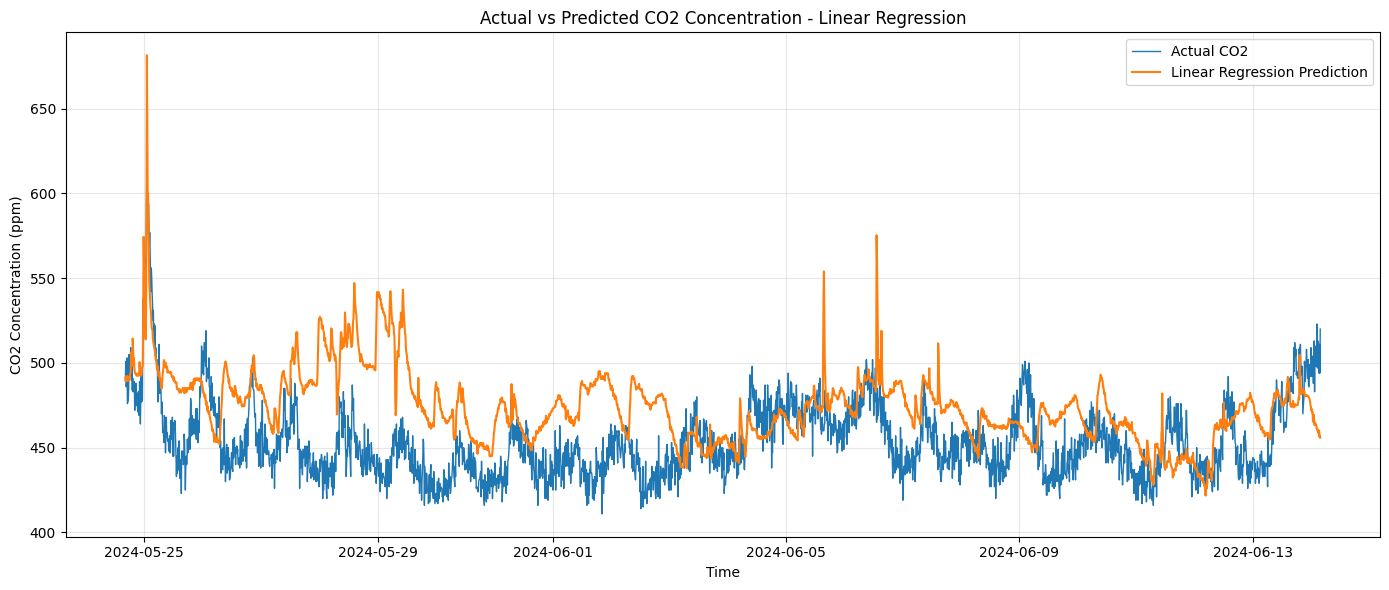

In [28]:
# ============================================================
# CELL 24 - ACTUAL VS PREDICTED CO2
# ============================================================

import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Plot actual and predicted CO2 over the testing period
# ------------------------------------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    test_data["Time"],
    y_test,
    label="Actual CO2",
    linewidth=1
)

plt.plot(
    test_data["Time"],
    y_pred_linear,
    label="Linear Regression Prediction",
    linewidth=1.5
)

plt.xlabel("Time")
plt.ylabel("CO2 Concentration (ppm)")
plt.title(
    "Actual vs Predicted CO2 Concentration - Linear Regression"
)

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Plotting a visual representation of the best regression model predicted V the actual CO2 concentration levels


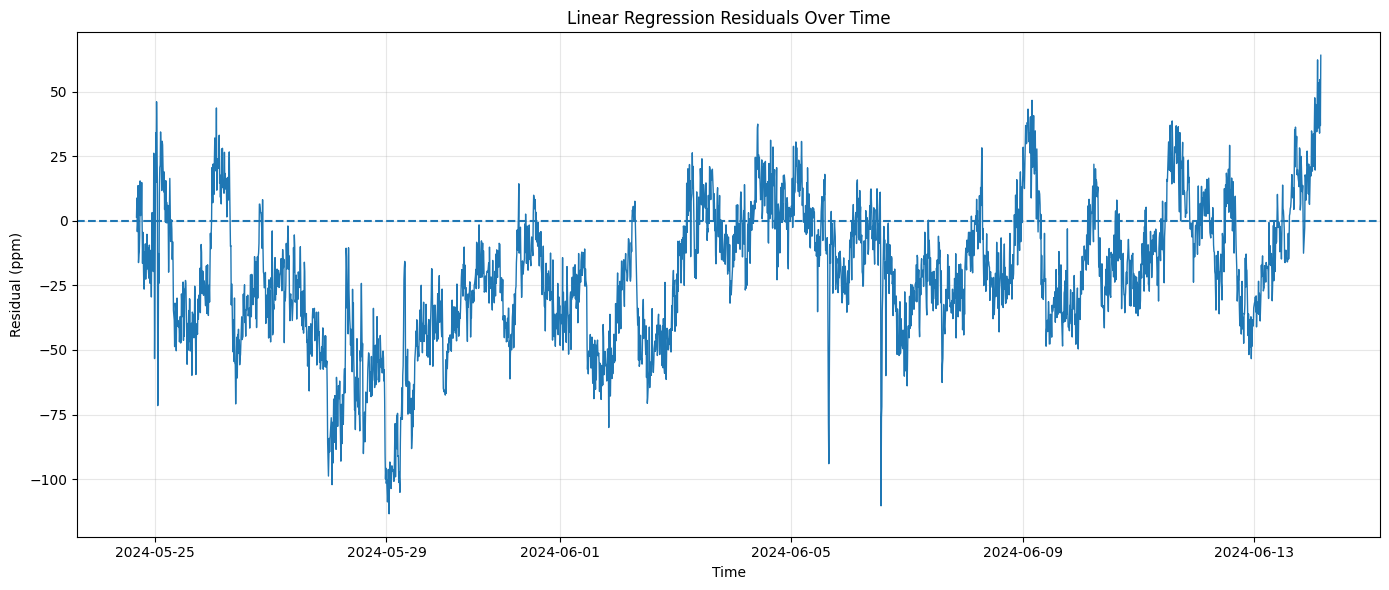

Mean residual: -20.92 ppm
Residual standard deviation: 26.30 ppm


In [29]:
# ============================================================
# CELL 25 - LINEAR REGRESSION RESIDUAL ANALYSIS
# ============================================================

# ------------------------------------------------------------
# 1. Calculate residuals
# ------------------------------------------------------------

residuals_linear = (
    y_test.to_numpy()
    - y_pred_linear
)


# ------------------------------------------------------------
# 2. Plot residuals over time
# ------------------------------------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    test_data["Time"],
    residuals_linear,
    linewidth=1
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Time")
plt.ylabel("Residual (ppm)")
plt.title(
    "Linear Regression Residuals Over Time"
)

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Display residual statistics
# ------------------------------------------------------------

print(
    f"Mean residual: {np.mean(residuals_linear):.2f} ppm"
)

print(
    f"Residual standard deviation: "
    f"{np.std(residuals_linear):.2f} ppm"
)

Residuals = Actual - predicted: therefore the regression model is overpredicting CO2 concentration levels.


,Feature,Importance
0,Temperature,0.418
1,Pressure,0.284
2,VOC,0.182
3,PM2_5,0.062
4,Humidity,0.054


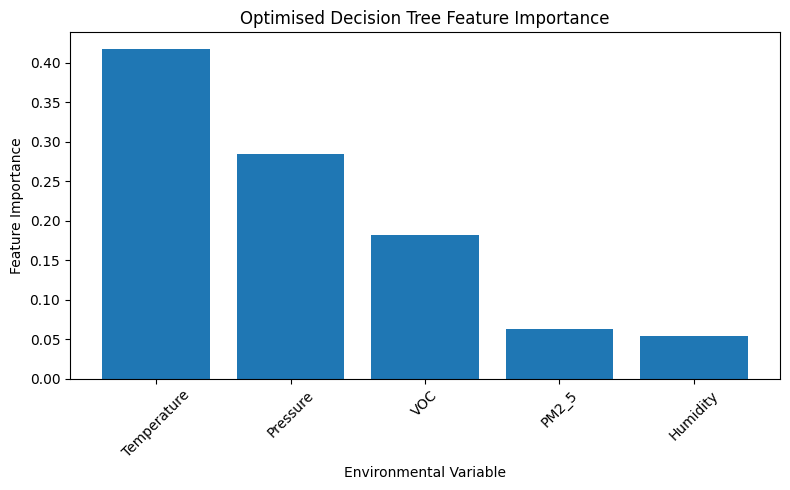

In [30]:
# ============================================================
# CELL 26 - DECISION TREE FEATURE IMPORTANCE
# ============================================================

# ------------------------------------------------------------
# 1. Extract feature importance values
# ------------------------------------------------------------

feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": optimised_tree.feature_importances_
})


# ------------------------------------------------------------
# 2. Sort from most important to least important
# ------------------------------------------------------------

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# 3. Display results
# ------------------------------------------------------------

display(
    feature_importance.round(3)
)


# ------------------------------------------------------------
# 4. Plot feature importance
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Environmental Variable")
plt.ylabel("Feature Importance")
plt.title(
    "Optimised Decision Tree Feature Importance"
)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

An interpretation of what the Decision Tree was relying on. While pressure had the strongest correlation with CO2, it is not the most heavily weighted.

In [31]:
# ============================================================
# CELL 27 - AUDIT GITHUB REPOSITORY
# ============================================================

from pathlib import Path
import subprocess


print("REPOSITORY:")
print(REPO)


# ------------------------------------------------------------
# 1. Git status
# ------------------------------------------------------------

print("\n================ GIT STATUS ================\n")

subprocess.run(
    ["git", "status"],
    cwd=REPO
)


# ------------------------------------------------------------
# 2. List repository files and sizes
# ------------------------------------------------------------

print("\n================ REPOSITORY FILES ================\n")

for path in sorted(REPO.rglob("*")):

    if ".git" in path.parts:
        continue

    if path.is_file():

        relative_path = path.relative_to(REPO)
        size_mb = path.stat().st_size / (1024 ** 2)

        print(
            f"{str(relative_path):60s}"
            f"{size_mb:8.2f} MB"
        )


# ------------------------------------------------------------
# 3. Recent commit history
# ------------------------------------------------------------

print("\n================ RECENT COMMITS ================\n")

subprocess.run(
    [
        "git",
        "log",
        "--oneline",
        "-10"
    ],
    cwd=REPO
)

REPOSITORY:
/content/MMA3001_repo

================ GIT STATUS ================


================ REPOSITORY FILES ================

.gitignore                                                      0.00 MB
LICENSE                                                         0.00 MB
README.md                                                       0.00 MB
data/raw/5EnvSensor_MayToDec2024_180kRows.zip                   7.04 MB
data/raw/Sensor ID and Locations.xlsx                           0.02 MB
hello.py                                                        0.00 MB

================ RECENT COMMITS ================



CompletedProcess(args=['git', 'log', '--oneline', '-10'], returncode=0)

In [32]:
# ============================================================
# CELL 28 - INSPECT REPOSITORY CONTENTS
# ============================================================

import subprocess


# ------------------------------------------------------------
# 1. Display README
# ------------------------------------------------------------

print("================ README.md ================\n")

readme_path = REPO / "README.md"

if readme_path.exists():
    print(readme_path.read_text())
else:
    print("README.md not found.")


# ------------------------------------------------------------
# 2. Display .gitignore
# ------------------------------------------------------------

print("\n================ .gitignore ================\n")

gitignore_path = REPO / ".gitignore"

if gitignore_path.exists():
    print(gitignore_path.read_text())
else:
    print(".gitignore not found.")


# ------------------------------------------------------------
# 3. Display hello.py
# ------------------------------------------------------------

print("\n================ hello.py ================\n")

hello_path = REPO / "hello.py"

if hello_path.exists():
    print(hello_path.read_text())
else:
    print("hello.py not found.")


# ------------------------------------------------------------
# 4. Show Git status clearly
# ------------------------------------------------------------

print("\n================ GIT STATUS ================\n")

status = subprocess.run(
    ["git", "status", "--short"],
    cwd=REPO,
    capture_output=True,
    text=True
)

print(
    status.stdout if status.stdout.strip()
    else "Working tree clean."
)


# ------------------------------------------------------------
# 5. Show recent commits clearly
# ------------------------------------------------------------

print("\n================ RECENT COMMITS ================\n")

log = subprocess.run(
    ["git", "log", "--oneline", "-10"],
    cwd=REPO,
    capture_output=True,
    text=True
)

print(log.stdout)

================ README.md ================

# MMA3001.Project
My Project For MMA3001


================ .gitignore ================

# Byte-compiled / optimized / DLL files
__pycache__/
*.py[codz]
*$py.class

# C extensions
*.so

# Distribution / packaging
.Python
build/
develop-eggs/
dist/
downloads/
eggs/
.eggs/
lib/
lib64/
parts/
sdist/
var/
wheels/
share/python-wheels/
*.egg-info/
.installed.cfg
*.egg
MANIFEST

# PyInstaller
#   Usually these files are written by a python script from a template
#   before PyInstaller builds the exe, so as to inject date/other infos into it.
*.manifest
*.spec

# Installer logs
pip-log.txt
pip-delete-this-directory.txt

# Unit test / coverage reports
htmlcov/
.tox/
.nox/
.coverage
.coverage.*
.cache
nosetests.xml
coverage.xml
*.cover
*.py.cover
.hypothesis/
.pytest_cache/
cover/

# Translations
*.mo
*.pot

# Django stuff:
*.log
local_settings.py
db.sqlite3
db.sqlite3-journal

# Flask stuff:
instance/
.webassets-cache

# Scrapy stuff:
.scrapy

# Sphi

In [33]:
# ============================================================
# CELL 29 - CLEAN REPOSITORY AND CREATE README
# ============================================================

# ------------------------------------------------------------
# 1. Remove unused hello.py file
# ------------------------------------------------------------

hello_path = REPO / "hello.py"

if hello_path.exists():
    hello_path.unlink()
    print("Removed hello.py")


# ------------------------------------------------------------
# 2. Create project README
# ------------------------------------------------------------

readme_text = """# MMA3001 Project

## Prediction of Indoor CO₂ Concentration Using Environmental Sensor Data

This repository contains the individual project completed for MMA3001.

The project investigates whether indoor carbon dioxide (CO₂) concentration can be predicted using environmental sensor measurements including:

- Temperature
- Humidity
- Pressure
- Volatile Organic Compounds (VOC)
- PM2.5

## Project Overview

Environmental sensor data were cleaned and processed before developing regression models to predict CO₂ concentration.

The analysis includes:

- JSON sensor data parsing
- Removal of duplicate sensor measurements
- Exploratory data analysis
- Chronological training and testing split
- Baseline prediction model
- Linear Regression
- Decision Tree Regression
- Decision Tree depth sensitivity analysis
- Model performance comparison
- Residual analysis
- Decision Tree feature importance

## Models

Two regression techniques covered in MMA3001 were investigated:

1. Linear Regression
2. Decision Tree Regression

A simple baseline model using the mean training CO₂ concentration was also included for comparison.

## Final Results

| Model | MAE (ppm) | RMSE (ppm) | R² |
|---|---:|---:|---:|
| Baseline | 29.862 | 34.001 | -1.369 |
| Linear Regression | 27.024 | 33.606 | -1.314 |
| Initial Decision Tree | 35.395 | 45.044 | -3.157 |
| Optimised Decision Tree | 31.595 | 39.419 | -2.184 |

Linear Regression achieved the best predictive performance of the tested models. However, its negative R² value and residual patterns indicate limited generalisation to the later testing period.

## Data

The environmental sensor dataset is stored in:

`data/raw/5EnvSensor_MayToDec2024_180kRows.zip`

Sensor location information is stored in:

`data/raw/Sensor ID and Locations.xlsx`

The raw environmental dataset contains repeated database records. Duplicate physical measurements were removed using sensor ID and measurement timestamp before modelling.

## Software

The project was developed in Python using Google Colab.

Main Python packages used:

- pandas
- numpy
- matplotlib
- scikit-learn

## Reproducibility

The notebook is designed to run sequentially from top to bottom.

The dataset is loaded directly from the repository, parsed, cleaned, analysed and used to train and evaluate the regression models.

## Author

MMA3001 Individual Project
"""

readme_path = REPO / "README.md"

readme_path.write_text(readme_text)

print("README.md updated")


# ------------------------------------------------------------
# 3. Show Git changes
# ------------------------------------------------------------

print("\n================ GIT CHANGES ================\n")

status = subprocess.run(
    ["git", "status", "--short"],
    cwd=REPO,
    capture_output=True,
    text=True
)

print(status.stdout)

Removed hello.py
README.md updated

================ GIT CHANGES ================

 M README.md
 D hello.py

